# 8 The Vicsek model

## The standard Vicsek model

<div style="background-color: #f0f8ff; border: 2px solid #4682b4; padding: 10px;">
<strong>Note:</strong> This notebook contains the code for sections 8.1 from the book  

**Simulation of Complex Systems**  
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)

You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)
</div>

Collective motion emerges from simple local alignment rule.

Vicsek model: mimics the motion in coordinated groups typical of fish, birds, and bacteria.

**Reference:** Vicsek *et al.* (1995), [*Novel type of phase transition in a system of self-driven particles*](https://doi.org/10.1103/PhysRevLett.75.1226).

<a id="vicsek-model-def"></a>
### 8.1 Particle positions, orientations, and periodic boundaries

Point-like particles moving on a square arena.

Square arena:
- side $L$
- *periodic boundary conditions*

A particle has:

- a position $x(t)$, $y(t)$ 
- an orientation $\theta(t)$

All particles have:

- the same constant speed $v$.
- the same flocking radius $R_f$

**Orientation rule:**

Each time step, a particle perform:

- re-orientation:
$$\theta_{j,\,n+1} = \langle \theta_{k,\,n} \rangle + \eta\, W_{j,\,n+1}\, \Delta t$$

- motion at constant speed:
$$\mathbf{r}_{j,\,n+1} = \mathbf{r}_{j,\,n} + \mathbf{v}_{j,\,n}\, \Delta t$$

In the formulas above:

- $j$ is the particle index
- $n$ is the time step
- $\langle \theta_{k,\,n} \rangle$ is a circular average: $\mathrm{arctan2} \left( \langle \mathrm{sin} \left( \theta_{k,\,n} \right) \rangle, \langle  \mathrm{cos} \left( \theta_{k,\,n} \right) \rangle \right)$ calculated over all particles $k$ *within the flocking radius* (i.e., belonging to the flocking *neighborhood* of particle $j$)
- the velocity $\mathbf{v}_{j,\,n}$ is:
$$\mathbf{v}_{j,\,n} = v\, \mathrm{cos}\, \theta_{j,\,n}\, \hat{\mathbf{x}} + v\, \mathrm{sin}\, \theta_{j,\,n}\, \hat{\mathbf{y}} $$

Let's try simulating the Vicsek model

In [1]:
import numpy as np
import matplotlib.pyplot as plt

We define the system parameters:

In [2]:
n_part = 100
box_length = 100.0
speed = 1.0
dt = 1.0
flocking_radius = 5.0 
noise = 0.01

rng = np.random.default_rng()

Let's initialize the system:

In [3]:
# initial positions
pos = rng.uniform(0, box_length, (n_part, 2))

# initial orientations
theta = rng.uniform(-np.pi, np.pi, n_part)

# initial velocities (from initial orientations)
vel = speed * np.column_stack((np.cos(theta), np.sin(theta)))

Let's plot the initial positions and orientations of the particles

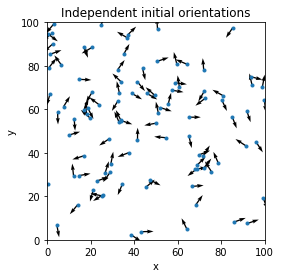

In [4]:
plt.figure(figsize=(4, 4))
plt.quiver(
    pos[:, 0], pos[:, 1], 
    vel[:, 0], vel[:, 1],
    angles='xy', 
    scale_units='xy', 
    scale=0.18  
)
plt.plot(pos[:, 0], pos[:, 1], '.')

plt.xlim(0, box_length)
plt.ylim(0, box_length)
plt.gca().set_aspect('equal')
plt.title('Independent initial orientations')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

<a id="neighborhood"></a>
Before proceeding further: 

we clarify how periodic boundary conditions are handled when determining which particles belong to the flocking neighborhood of a given particle.

To calculate neighborhoods we need the **minimum-image displacement**: the shortest signed separation on the periodic square. This is essential for particles near opposite boundaries (textbook Figure 8.2).

In [5]:
left = np.array([10.5, 50.0])
right = np.array([89.5, 30.0])
difference = right - left

shortest = (
    difference 
    - box_length * np.rint(difference / box_length)
)
print('Naive distance:', np.linalg.norm(difference))
print('Periodic distance:', np.linalg.norm(shortest))

Naive distance: 81.49233092751734
Periodic distance: 29.0


Let's plot the configuration to understand better the result it:

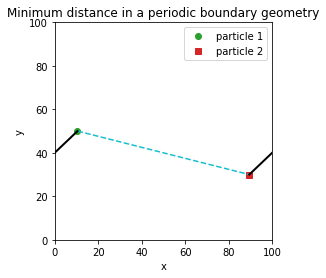

In [6]:
plt.figure(figsize=(4, 4))
plt.plot(left[0], left[1], 'o', color='C2', label='particle 1')
plt.plot(right[0], right[1], 's', color='C3', label='particle 2')
plt.plot([left[0], right[0]], 
         [left[1], right[1]], '--', color='C9')
plt.plot([right[0] - box_length, left[0]], 
         [right[1], left[1]], 'k-', lw=2)
plt.plot([right[0], left[0] + box_length], 
         [right[1], left[1]], 'k-', lw=2)

plt.xlim(0, box_length)
plt.ylim(0, box_length)
plt.gca().set_aspect('equal')
plt.title('Minimum distance in a periodic boundary geometry')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

Now, let's see how a single step is performed.

Particles move with their current speed:

In [7]:
displaced = pos + dt * vel

We enforce the *periodic boundary conditions*.

In [8]:
wrapped = displaced % box_length
print(
    'Coordinates inside the square:', 
    np.all((0 <= wrapped) & (wrapped < box_length)))

Coordinates inside the square: True


<a id="orientation-rule"></a>
Particle reorient according to the average orientation in their neighborhood.

Let's choose one particle and list its neighbors

In [9]:
j = 0
neigh = []
for k in range(n_part):
    difference = pos[k] - pos[j]
    difference -= box_length * np.rint(difference / box_length)
    if np.linalg.norm(difference) < flocking_radius:
        neigh.append(k)
print('Neighbors of particle 0 (including itself):', neigh)

Neighbors of particle 0 (including itself): [0, 76]


Let's calculate the average orientation:

In [10]:
local_theta = theta[neigh]

sine = np.sin(local_theta).sum()

cosine = np.cos(local_theta).sum()

mean_orientation = np.arctan2(sine, cosine)

print(f'Circular mean: {mean_orientation:.3f}')

Circular mean: 2.983


To illustrate why it is crucial to use a *circular average* rather than a standard arithmetic mean, let's consider a simple example:

Arithmetic mean: 0.000 (degrees)
Circular mean: 180.000 (degrees)


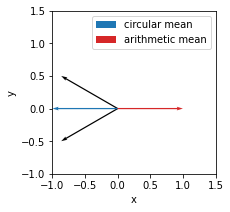

In [11]:
test_theta = np.deg2rad([150, -150])

theta_am = test_theta.mean()

theta_cm = np.arctan2(
    np.sin(test_theta).sum(), 
    np.cos(test_theta).sum()
)

print(f'Arithmetic mean: {np.rad2deg(theta_am):.3f} (degrees)')

print(f'Circular mean: {np.rad2deg(theta_cm):.3f} (degrees)')

plt.figure(figsize=(3, 3))
plt.quiver(
    [0, 0], [0, 0], 
    np.cos(test_theta), 
    np.sin(test_theta),
    angles='xy', 
    scale_units='xy', 
    scale=1
)
plt.quiver(
    0, 0, np.cos(theta_cm), np.sin(theta_cm), 
    angles='xy', 
    scale_units='xy', 
    scale=1,
    color='C0',
    label='circular mean'
)
plt.quiver(
    0, 0, np.cos(theta_am), np.sin(theta_am), 
    angles='xy', 
    scale_units='xy', 
    scale=1,
    color='C3',
    label='arithmetic mean'
)

plt.xlim([-1, 1.5])
plt.ylim([-1, 1.5])
plt.gca().set_aspect('equal')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()


Let's add the noise:

In [12]:
W_phi = rng.uniform(-0.5, 0.5)
new_orientation = mean_orientation + noise * W_phi * dt
print('Single-particle updated orientation:', new_orientation)

Single-particle updated orientation: 2.9790420706161664


<a id="single-update"></a>
Let's see now how to build one complete synchronous update:

In [13]:
next_theta = np.empty(n_part)
for j in range(n_part):
    members = []
    for k in range(n_part):
        separation = pos[k] - pos[j]
        separation -= box_length * np.rint(separation / box_length)
        if np.dot(separation, separation) < flocking_radius ** 2:
            members.append(k)
    direction = np.arctan2(np.sin(theta[members]).sum(),
                           np.cos(theta[members]).sum())
    next_theta[j] = direction + noise * dt * rng.uniform(-0.5, 0.5)
    
next_pos = (
    pos + dt * speed * np.column_stack(
        (np.cos(theta), np.sin(theta))
    )
) % box_length

pos, theta = next_pos, next_theta

print('Completed one simultaneous step for', 
      f'{len(theta)} particles.')

Completed one simultaneous step for 100 particles.


<a id="first-simulation"></a>
We are now ready to run a first simulation of the Vicsek model.

We use the functions in the module:

In [14]:
from pathlib import Path
import sys
sys.path.insert(0, '../08_modules')

import vicsek_model as vm
import vm_visualize as vis

pygame 2.5.2 (SDL 2.28.3, Python 3.8.5)
Hello from the pygame community. https://www.pygame.org/contribute.html


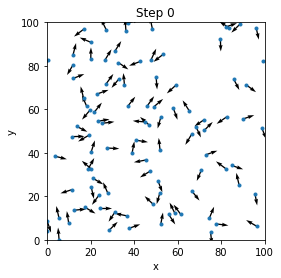

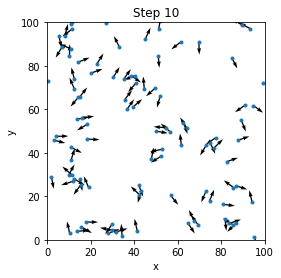

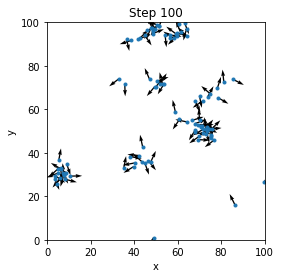

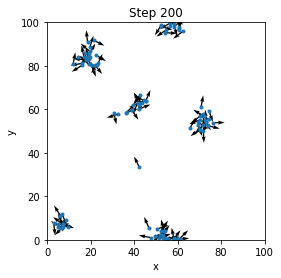

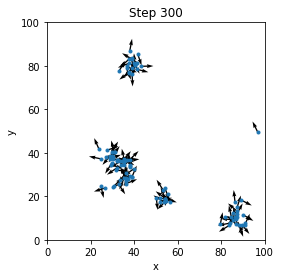

In [15]:
n_part = 100
box_length = 100.0
speed = 1.0
dt = 1.0
flocking_radius = 5.0 
noise = 0.01

dt = 1.0
n_steps = 300
n_show = [0, 10, 100, 200, 300]

rng = np.random.default_rng()

# initialization
pos, theta = vm.initial_state(n_part, box_length)

for step in range(n_steps + 1):
    if step in n_show:
        # plot frame
        fig, ax = vis.plot_particles(
            pos, vel, box_length, step=step
        )
        plt.show()
    pos, theta = vm.step_metric(
        pos, theta, box_length, speed, flocking_radius, noise, 
        dt=dt
    )

You can see here an animation

In [16]:
n_part = 50
box_length = 100.0
speed = 0.1
dt = 1.0
flocking_radius = 1.0 
noise = 0.1

dt = 1.0
n_steps = 1000
n_skip = 1
image_size = 300

rng = np.random.default_rng()

# initialization
start_pos, start_theta = vm.initial_state(n_part, box_length)

anim_pos, anim_theta = vis.animate_vicsek(
    start_pos.copy(), 
    start_theta.copy(), 
    box_length,
    model='metric', 
    speed=speed, 
    flocking_radius=flocking_radius, 
    noise=noise,
    dt=dt, 
    frames=n_steps, 
    steps_per_frame=n_skip,
    image_size=image_size
)

<a id="observables"></a>
Let's define two observables to describe the system. The first observable is the:


**Global alignment coefficient** $\psi$:

$$\psi=\frac{1}{N}\left|\sum_j \frac{\mathbf{v}_{j}}{{v}_{j}}\right|$$ 

which is equivalent to:

$$\psi=\frac{1}{N}\left|\sum_j e^{i\theta_j}\right|$$ 

It's implemented using `np.hypot()`

In [17]:
psi = np.hypot(
    np.cos(theta).mean(), 
    np.sin(theta).mean()
)
print(f'Current alignment: {psi:.3f}')


Current alignment: 0.985


The second observable is the:

**Global clustering coefficient** $c$:

See Equation (8.6) in the book.

$$c = \frac{1}{N} \, \mathrm{count} \left\{ A_{j} < \pi R_f^2 \right\}$$

where $A_{j}$ is the Voronoi area of the cell $j$.


In [18]:
c, areas = vm.voronoi_clustering(pos, box_length, flocking_radius)

# c = np.mean(
#     areas < np.pi * flocking_radius**2
# )


print('Voronoi area sum / arena area:', 
      f'{areas.sum() / box_length**2:.3f}')
print(f'Clustering coefficient: {c:.3f}')

Voronoi area sum / arena area: 1.000
Clustering coefficient: 0.270


Let's see how the two observable evolve in time:

In [19]:
n_part = 100
box_length = 100.0
speed = 1.0
dt = 1.0
flocking_radius = 1.0 
noise = 0.01

dt = 1.0
n_steps = 4000
n_skip = 10

rng = np.random.default_rng()

start_pos, start_theta = vm.initial_state(
    n_part, box_length
)

pos = start_pos.copy() 
theta = start_theta.copy()

psi_series = [vm.alignment(theta)]
c, _ = vm.voronoi_clustering(pos, box_length, flocking_radius)
c_series = [c]

for step in range(1, n_steps + 1):
    pos, theta = vm.step_metric(
        pos, theta, box_length, speed, flocking_radius, noise, 
        dt)
    if step % n_skip == 0:
        psi_series.append(vm.alignment(theta))
        c, _ = vm.voronoi_clustering(pos, box_length, flocking_radius)
        c_series.append(c)

...and plot them:

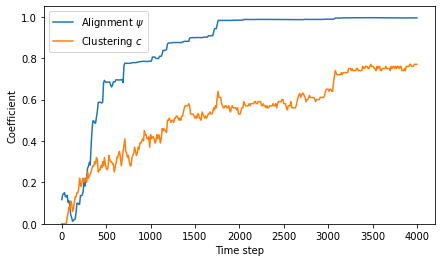

In [20]:
fig, ax = plt.subplots(figsize=(7, 4))

steps = np.arange(0, n_steps + 1, n_skip)

ax.plot(steps, psi_series, label=r'Alignment $\psi$')
ax.plot(steps, c_series, label=r'Clustering $c$')

ax.set(
    xlabel='Time step', 
    ylabel='Coefficient', 
    ylim=(0, 1.05)
)

ax.legend()
plt.show()

We plot the initial and final configuration:

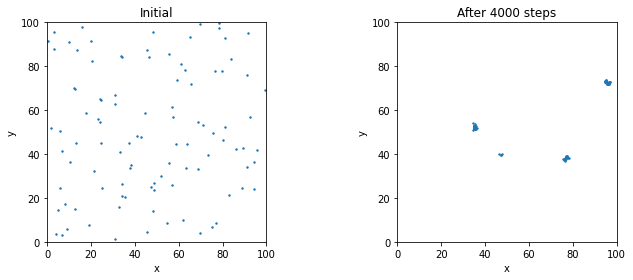

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, data, name in zip(
    axes, (start_pos, pos), ('Initial', f'After {n_steps} steps')
):
    ax.scatter(data[:, 0], data[:, 1], s=2)
    ax.set(
        xlim=(0, box_length), 
        ylim=(0, box_length), 
        title=name,
        xlabel='x', 
        ylabel='y')
    ax.set_aspect('equal')
    
plt.tight_layout()
plt.show()

<a id="density-noise"></a>
Let's check few cases of *particle density* and *noise*

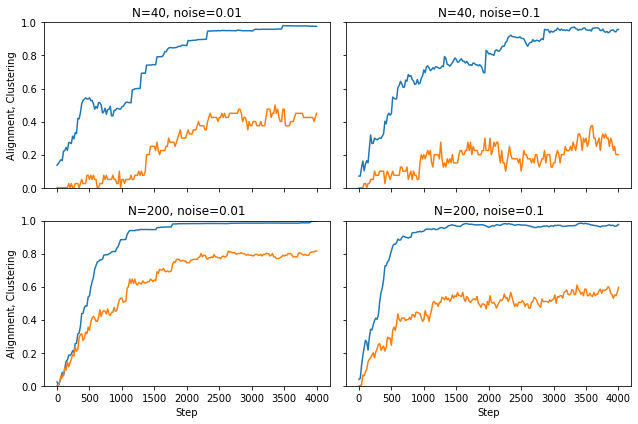

In [22]:
n_part_values = [40, 200]
noise_values = [0.01, 0.1]

cases = [
    (n_part, noise)
    for n_part in n_part_values
    for noise in noise_values
]

box_length = 100.0
speed = 1.0
dt = 1.0
flocking_radius = 1.0 

dt = 1.0
n_steps = 4000
n_skip = 20


fig, axes = plt.subplots(
    2, 2, 
    figsize=(9, 6), 
    sharex=True, 
    sharey=True
)

for ax, (n_case, eta_case) in zip(axes.flat, cases):
    p, a = vm.initial_state(n_case, box_length)
    psi = [vm.alignment(a)]
    c_coeff, _ = vm.voronoi_clustering(
        p, box_length, flocking_radius
    )
    c = [c_coeff]
    for step in range(n_steps):
        p, a = vm.step_metric(
            p, a, box_length, speed,
            flocking_radius, eta_case, dt)
        if step % n_skip == 0:
            psi.append(vm.alignment(a))
            c_coeff, _ = vm.voronoi_clustering(
                p, box_length, flocking_radius
            )
            c.append(c_coeff)   
    steps = np.arange(0, n_steps + 1, n_skip)
    ax.plot(steps, psi)
    ax.plot(steps, c)
    ax.set_title(f'N={n_case}, noise={eta_case}')
    ax.set_ylim(0, 1)
    
for ax in axes[-1]: ax.set_xlabel('Step')
for ax in axes[:, 0]: ax.set_ylabel('Alignment, Clustering')
plt.tight_layout(); 
plt.show()

<a id="questions"></a>
## Questions

- [Q1: Neighborhood and periodic boundary conditions](#q1)
- [Q2: Orientation rule and circular average](#q2)
- [Q3: Single step update and first simulation](#q3)
- [Q4: Observables: alignment and clustering coefficient](#q4)
- [Q5: Dependence on density and noise](#q5)

<a id="q1"></a>
### Q1: Neighborhood and periodic boundary conditions

Refer to [neighborhood](#neighborhood).

[Go back to questions](#questions)

**a.** Explain the concept behind the **minimum-image displacement**. Why is it important for periodic boundary conditions?

**b.** Explain the meaning of the code:
```python
left = np.array([10.5, 50.0])
right = np.array([89.5, 30.0])
difference = right - left

shortest = (
    difference 
    - box_length * np.rint(difference / box_length)
)
```
In particular, explain `np.rint(difference / box_length)` .

**c.** In a simulation, we have `box_length = 100.0` . 
Why setting `flocking_radius = 55.0` is **not** a good idea?


<a id="q2"></a>
### Q2: Orientation rule and circular average

Refer to [orientation-rule](#orientation-rule) and [Vicsek model definition](#vicsek-model-def)

[Go back to questions](#questions)

**a.** Explain the difference of taking a *circular mean* instead of taking an *arithmetic mean*. Why are they different when we are considering orientation angles?

**b.** I want to change the implementation of the *circular mean* to:
```python
theta_cm = np.arctan2(
    np.sin(test_theta), 
    np.cos(test_theta)
).sum()
```
Is this a good decision? Why or why not?


**c.** Explain the meaning and implementation of the orientation rule for the standard Vicsek model. 



<a id="q3"></a>
### Q3: Single step update and first simulation

Refer to [single update](#single-update) and [first simulation](#first-simulation) 

[Go back to questions](#questions)

**a.** In the single step update, I use the current orientation `theta` to calculate the velocity and then the displacement. Is it equivalent to first update the `theta` and then use the *new* value of theta to to calculate the velocity and then the displacement?

**b.** In the implementation, do the Vicsek particles have a finite size? Or are they point-like? What happens if two particles occupy the exact same position?

**c.** Assume that there are only two particles in a simulation with 
```python
box_length = 100.0
flocking_radius = 10.0
speed = 5.0
noise = 0.5 * np.pi
n_steps = 1000
```
Those two particles initially are at a distance equal to `d = 0.5 * flocking_radius`. You run the simulation. After `n_steps` steps, is it likely that the two particles are still distant less than `d` ? Why or why not?


<a id="q4"></a>
### Q4: Observables: alignment and clustering coefficient

Refer to [observables](#observables)

[Go back to questions](#questions)

**a.** Explain the meaning and implementation of the global alignment coefficient. 

**b.** Explain why the calculation of the global clustering coefficient depends on the value of `flocking_radius`.

**c.** Can you think of a different definition for the *clustering coefficient*, without using the Voronoi tesselation? Think of an alternative definition for the *clustering coefficient*.  Think of a possible implementation. Discuss advantages and disadvantages.


<a id="q5"></a>
### Q5: Dependence on density and noise

Refer to [dependence on density and noise](#density-noise)

[Go back to questions](#questions)

In a simulation for the Vicsek model you have:
```python
n_part = 100.0
noise = 0.1
box_length = 100.0
flocking_radius = 1.0
speed = 1.0
dt = 1.0
n_steps = 5000
```

**a.** You increase the number of particles: `n_part = 1000.0` keeping all other parameters constant. Draw a possible trend for the *global alignment coefficient* as a function of the number of steps. Explain your reasoning.

**b.** You decrease the noise: `noise = 0.01` keeping all other parameters constant. Draw a possible trend for the *clustering coefficient* as a function of the number of steps. Explain your reasoning.

**c.** You increase the size of the arena: `box_length = 1000.0` keeping all other parameters constant. Draw a possible trend for the *global alignment coefficient* as a function of the number of steps. Explain your reasoning.
